# Computer Vision 2026-2027 - NOVA FCT

## Project Stage 1 - Shot boundary detection and recurring scenes

**Authors**:
- 73803, Rogério Barros Maia Lopes Soares, rbm.soares@campus.fct.unl.pt
- 74514, Guilherme Simões, gaq.simoes@campus.fct.unl.pt

## 1. Introduction

### We write the intro HERE ! 

In [1]:
import tp1, metrics, cv2, matplotlib.pyplot as plt, numpy as np, signals

VIDEO_01 = "../input/dev_01.mp4"
VIDEO_02 = "../input/dev_02.mp4"


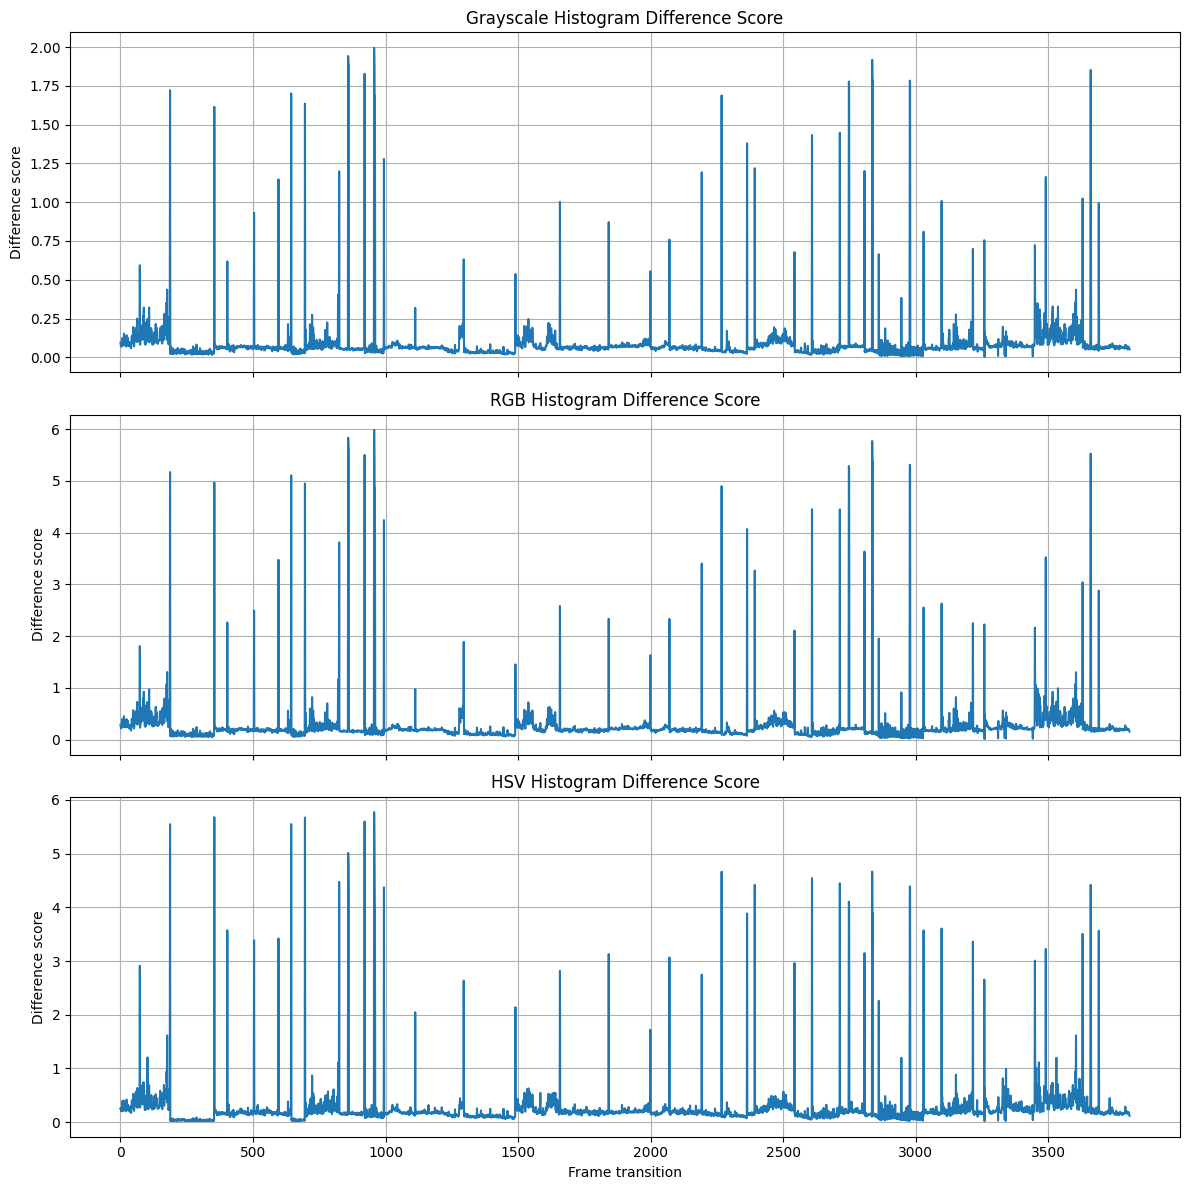

In [2]:
rgb_red_histogram_diff, rgb_green_histogram_diff, rgb_blue_histogram_diff = signals.absolute_histogram_differences(tp1.read_frames(VIDEO_01), num_bins=256, color_space='RGB')
h_histogram_diff, s_histogram_diff, v_histogram_diff = signals.absolute_histogram_differences(tp1.read_frames(VIDEO_01), num_bins=256, color_space='HSV')
gray_histogram_diff = signals.absolute_histogram_differences(tp1.read_frames(VIDEO_01), num_bins=256, color_space='GRAY')

gray_diff_score = np.sum(
    np.abs(gray_histogram_diff),
    axis=1
)

rgb_diff_score = np.sum(
    np.abs(rgb_red_histogram_diff)
    + np.abs(rgb_green_histogram_diff)
    + np.abs(rgb_blue_histogram_diff),
    axis=1
)

hsv_diff_score = (
    np.sum(np.abs(h_histogram_diff), axis=1)
    + np.sum(np.abs(s_histogram_diff), axis=1)
    + np.sum(np.abs(v_histogram_diff), axis=1)
)


fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(12, 12),
    sharex=True
)

axes[0].plot(gray_diff_score)
axes[0].set_title("Grayscale Histogram Difference Score")
axes[0].set_ylabel("Difference score")
axes[0].grid(True)

axes[1].plot(rgb_diff_score)
axes[1].set_title("RGB Histogram Difference Score")
axes[1].set_ylabel("Difference score")
axes[1].grid(True)

axes[2].plot(hsv_diff_score)
axes[2].set_title("HSV Histogram Difference Score")
axes[2].set_xlabel("Frame transition")
axes[2].set_ylabel("Difference score")
axes[2].grid(True)

plt.tight_layout()
plt.show()

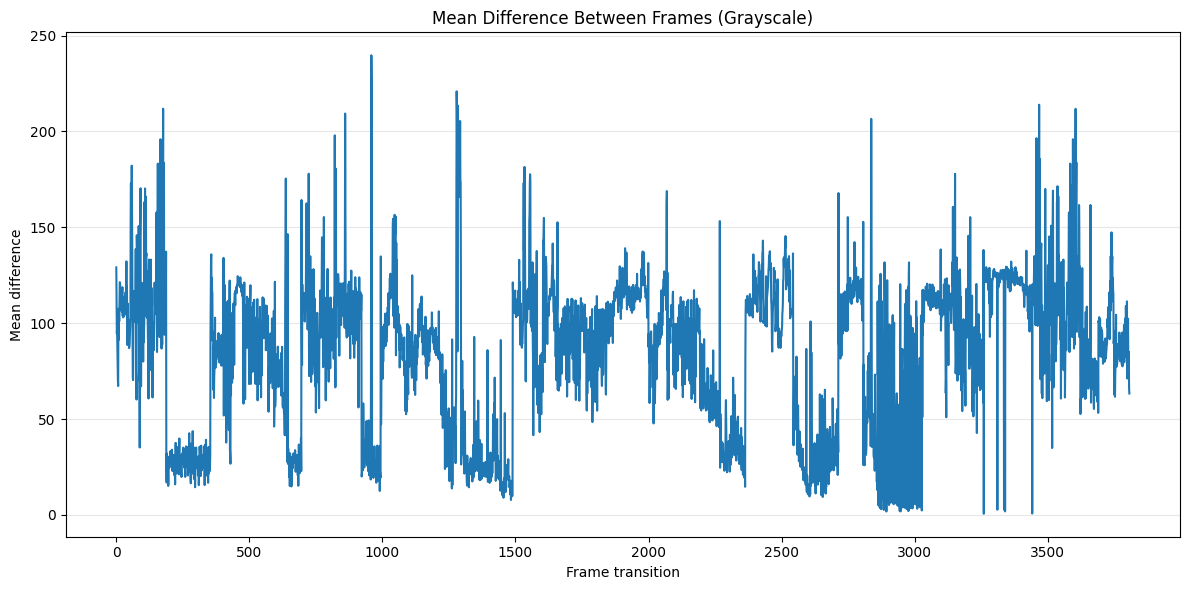

In [3]:
mean_diff_gray_scale = signals.absolute_mean_difference_between_frames(
    tp1.read_frames(VIDEO_01), color_space='GRAY'
)

frame_transitions = np.arange(len(mean_diff_gray_scale))

plt.figure(figsize=(12, 6))
plt.plot(frame_transitions, mean_diff_gray_scale)

plt.title("Mean Difference Between Frames (Grayscale)")
plt.xlabel("Frame transition")
plt.ylabel("Mean difference")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

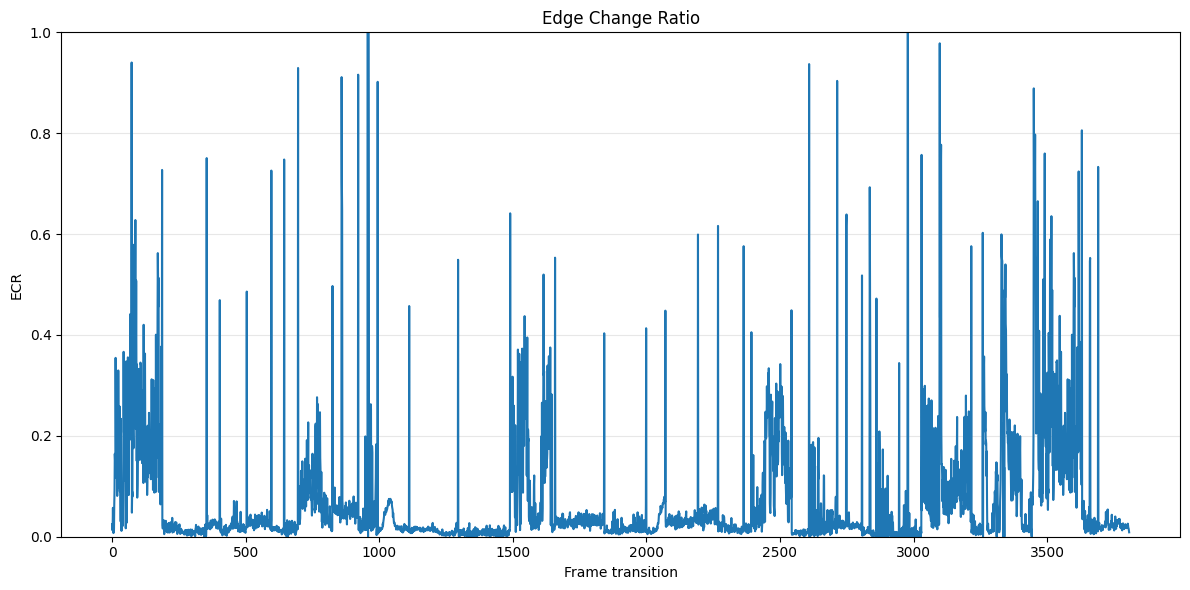

In [4]:
ecr_scores = signals.edge_change_ratio(
    tp1.read_frames(VIDEO_01),
    kernel_size=5
)

frame_transitions = np.arange(len(ecr_scores))

plt.figure(figsize=(12, 6))
plt.plot(frame_transitions, ecr_scores)

plt.title("Edge Change Ratio")
plt.xlabel("Frame transition")
plt.ylabel("ECR")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

signal      threshold  precision  recall  F1
histogram      0.530     0.559   0.943 0.702
pixel        132.113     0.094   0.571 0.161
ecr            0.714     0.661   0.557 0.605


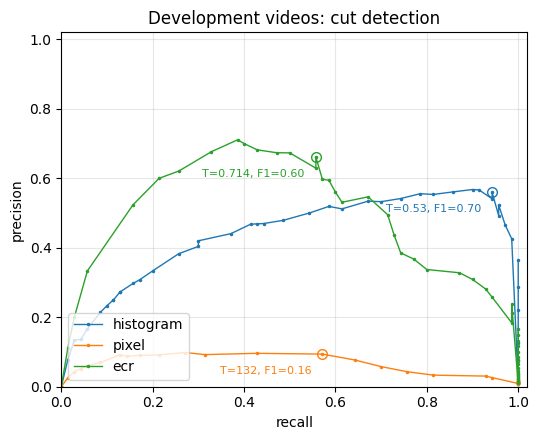

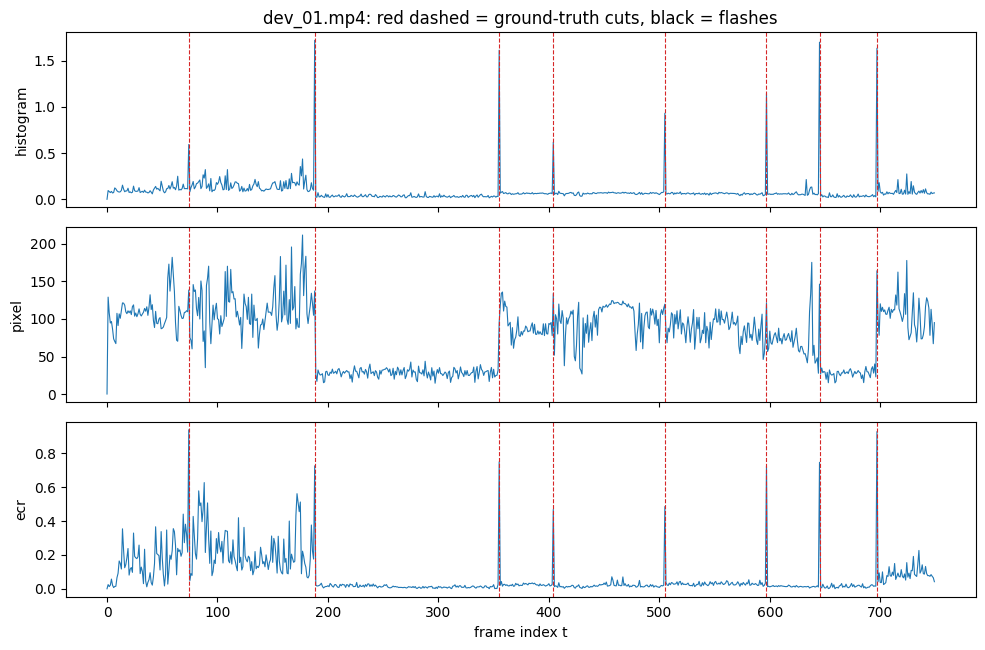

In [5]:
import json
import plotting

ground_truth = {
    name: json.load(open(f"../input/{name}.json"))
    for name in ["dev_01", "dev_02"]
}

videos = {
    name: tp1.read_frames(f"../input/{name}.mp4")
    for name in ground_truth
}

signals_by_video = {}

for name, frames in videos.items():
    gray_histogram = signals.absolute_histogram_differences(
        frames,
        num_bins=256,
        color_space="GRAY"
    )
    histogram_score = np.sum(np.abs(gray_histogram), axis=1)
    pixel_score = signals.absolute_mean_difference_between_frames(
        frames,
        color_space="GRAY"
    )
    ecr_score = signals.edge_change_ratio(frames, kernel_size=5)

    signals_by_video[name] = {
        # d[t] compares frames[t - 1] and frames[t].
        "histogram": np.concatenate(([0.0], histogram_score)),
        "pixel": np.concatenate(([0.0], pixel_score)),
        "ecr": np.concatenate(([0.0], ecr_score)),
    }

curves = {"histogram": [], "pixel": [], "ecr": []}
best_results = {}

for signal_name in curves:
    all_values = np.concatenate([
        signals_by_video[name][signal_name]
        for name in signals_by_video
    ])
    thresholds = np.linspace(0, all_values.max(), 50)
    best_f1 = -1

    for threshold in thresholds:
        counts = []

        for name in signals_by_video:
            signal = signals_by_video[name][signal_name]
            predicted_cuts = np.where(signal > threshold)[0]
            ground_truth_cuts = [
                transition["start"]
                for transition in ground_truth[name]["transitions"]
            ]
            counts.append(
                metrics.match_cuts(ground_truth_cuts, predicted_cuts)
            )

        tp = sum(count[0] for count in counts)
        fp = sum(count[1] for count in counts)
        fn = sum(count[2] for count in counts)
        precision, recall, f1 = metrics.precision_recall_f1(tp, fp, fn)
        curves[signal_name].append((threshold, precision, recall))

        if f1 > best_f1:
            best_f1 = f1
            best_results[signal_name] = (
                threshold,
                precision,
                recall,
                f1,
            )

print("signal      threshold  precision  recall  F1")
for signal_name, result in best_results.items():
    threshold, precision, recall, f1 = result
    print(
        f"{signal_name:10s} {threshold:9.3f} "
        f"{precision:9.3f} {recall:7.3f} {f1:5.3f}"
    )

plotting.plot_pr_curve(
    curves,
    title="Development videos: cut detection"
)
plt.show()

dev_01_signals = signals_by_video["dev_01"]
plotting.plot_signals(
    dev_01_signals,
    ground_truth["dev_01"],
    start=0,
    end=min(
        int(ground_truth["dev_01"]["fps"] * 30),
        len(next(iter(dev_01_signals.values())))
    )
)
plt.show()


## 2. Part 1 - Frame dissimilarity and hard cuts

## 3. Part 2 - Gradual transitions and false alarms

In [12]:
import verification

# Best grayscale result from part 1
threshold = best_results["histogram"][0]

signal = signals_by_video["dev_01"]["histogram"]
frames = videos["dev_01"]
candidates = np.where(signal > threshold)[0]

kept = verification.verify_cuts(frames, candidates, gap=4, min_matches=20)
print(kept)


[]


## 4. Part 3 - Recurring scenes

## 5. Results (development and test)

## 6. Analysis and failure cases

## 7. Conclusion and self-evaluation

## 8. Extras

## 9. Use of AI tools